In [1]:
import numpy as np

def get_firing_matrix(firing_rates_dict):
    """
    Extracts and transposes the firing rate matrix from a dictionary.
    Returns a matrix of shape (T_bins, N_units).
    """
    all_units = list(firing_rates_dict.keys())
    firing_matrix = np.array([firing_rates_dict[unit]['firing_rate'] for unit in all_units])
    return firing_matrix.T  # (T_bins, N_units)
def compute_firing_rates(st_time, starttime, endtime, bin_size=1.0):
    """
    Computes firing rates for multiple units using vectorized operations.

    Parameters:
        st_time (list of np.ndarray): A list where each entry is an array of spike times for a unit.
        starttime (float): The start time of the epoch.
        endtime (float): The end time of the epoch.
        bin_size (float, optional): The size of the bins in seconds. Default is 1.0.

    Returns:
        dict: A dictionary where each key is 'unitX' and values contain firing rates and time bin centers.
    """
    # Generate time bins
    bins = np.arange(starttime, endtime + bin_size, bin_size)
    time_bin_centers = bins[:-1] + (bin_size / 2)  # Compute the center of each time bin

    # Convert spike times list to a NumPy array (object dtype for jagged arrays)
    spike_times_array = np.array(st_time, dtype=object)

    # Compute spike counts using vectorized histogram
    spike_counts = np.array([
        np.histogram(spike_times[(spike_times >= starttime) & (spike_times < endtime)], bins=bins)[0]
        for spike_times in spike_times_array
    ])

    # Calculate firing rates (spike count per second)
    firing_rates = spike_counts / bin_size  # Shape: (num_units, num_bins)

    # Store results in a dictionary
    firing_rates_dict = {
        f'unit{idx + 1}': {'firing_rate': firing_rates[idx], 'time_stamps': time_bin_centers}
        for idx in range(len(spike_times_array))
    }

    return firing_rates_dict
import numpy as np

def filter_nrem_hse_fast(firing_rates_dict, NREM_HSE_epochs):
    """
    Filters firing rates to keep only bins within NREM_HSE epochs (optimized for speed).

    Parameters:
        firing_rates_dict (dict): Output from `compute_firing_rates`, containing firing rates and time stamps.
        NREM_HSE_epochs (np.ndarray): An array of shape (num_epochs, 2) where each row is [start, stop] time.

    Returns:
        dict: Filtered version of `firing_rates_dict`, keeping only time bins within NREM_HSE epochs.
    """
    filtered_firing_rates = {}

    # Sort NREM_HSE_epochs for faster searching
    sorted_epochs = np.sort(NREM_HSE_epochs, axis=0)

    for unit, data in firing_rates_dict.items():
        firing_rate = data['firing_rate']
        time_stamps = data['time_stamps']

        # Fast lookup: Find which epochs each time bin belongs to
        idx_starts = np.searchsorted(sorted_epochs[:, 0], time_stamps, side="right") - 1
        idx_ends = np.searchsorted(sorted_epochs[:, 1], time_stamps, side="left")

        # A valid time bin is inside an epoch if the start index == end index
        mask = (idx_starts == idx_ends) & (idx_starts >= 0) & (idx_starts < len(sorted_epochs))

        # Apply mask to filter time bins
        filtered_firing_rates[unit] = {
            'firing_rate': firing_rate[mask],
            'time_stamps': time_stamps[mask]
        }

    return filtered_firing_rates
def compute_ripple_rate(ripple_timestamps, bin_centers, bin_size=1.0):
    """
    Computes ripple rate (ripples per second) in each bin.

    Parameters:
        ripple_timestamps (np.ndarray): 1D array of ripple event times (e.g., ripple peaks).
        bin_centers (np.ndarray): 1D array of time points corresponding to the center of each bin.
        bin_size (float): Bin size in seconds.

    Returns:
        np.ndarray: Ripple rate (Hz) per bin.
    """
    half_bin = bin_size / 2.0
    # Construct bin edges from centers
    bin_edges = np.concatenate(([bin_centers[0] - half_bin], bin_centers + half_bin))

    ripple_counts, _ = np.histogram(ripple_timestamps, bins=bin_edges)
    return ripple_counts / bin_size  # ripple rate in Hz
import numpy as np
import pandas as pd

import numpy as np
import pandas as pd
def compute_population_synchrony_from_hist(E_spikes, bin_size=0.025):
    """
    Compute population synchrony from spike trains by:
    1. Binning into 25ms bins using np.histogram
    2. Aggregating every 2 bins (50ms) to compute synchrony

    Parameters:
        E_spikes (list of np.arrays): spike times for each unit
        bin_size (float): bin size in seconds (default 25ms)

    Returns:
        pd.DataFrame: columns ['time', 'synchrony']
    """
    num_units = len(E_spikes)

    # Get global time range
    all_spikes = np.concatenate(E_spikes)
    t_min = np.min(all_spikes)
    t_max = np.max(all_spikes)

    # Bin edges for 25ms
    bin_edges = np.arange(t_min, t_max + bin_size, bin_size)
    n_bins = len(bin_edges) - 1

    # Fill firing rate matrix
    firing_matrix = np.zeros((num_units, n_bins), dtype=int)
    for unit_idx, spikes in enumerate(E_spikes):
        counts, _ = np.histogram(spikes, bins=bin_edges)
        firing_matrix[unit_idx] = counts

    # Compute synchrony across every 50ms (2-bin) chunk
    step = 2
    sync = []
    time_centers = []

    for i in range(0, n_bins - 1, step):
        activity = np.sum(firing_matrix[:, i:i+2], axis=1)
        frac_active = np.sum(activity > 0) / num_units
        sync.append(frac_active)
        time_centers.append((bin_edges[i] + bin_edges[i+2]) / 2)

    return pd.DataFrame({
        'time': time_centers,
        'synchrony': sync
    })



In [2]:


import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
from skimage import measure
import os

import logging

logging.getLogger().setLevel(logging.ERROR)
basepath = r"W:\data\PPP\PPP23\day8"
basename=os.path.basename(basepath)# Define the new folder path
#create working folder
new_folder_path = os.path.join(basepath, "complex_system")
brain_region="CA1"
animal="mouse"   #or Mouse
cell_type='all'
path_parts = basepath.split("\\")  # Split the path using backslash
animal_name = path_parts[-2]  # Second-to-last part is the animal name
day = path_parts[-1]  # Last part is the day
save_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples"
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
# Create the folder if it doesn't exist
if not os.path.exists(new_folder_path):
    os.makedirs(new_folder_path)
    print(f"Folder created: {new_folder_path}")
else:
    print(f"Folder already exists: {new_folder_path}")
# load in spike data from hpc pyramidal cells
st, cm = loading.load_spikes(
    basepath, brainRegion="CA1"                          # putativeCellType="Pyr"
)
# load theta epochs
state_dict = loading.load_SleepState_states(basepath)
nrem_epochs = nel.EpochArray(
    state_dict["NREMstate"],
)
awake_epochs = nel.EpochArray(
    state_dict["WAKEstate"],
)
import scipy.io
""" file_path = os.path.join(basepath, f"HSE_epochs.mat")
mat_data = scipy.io.loadmat(file_path)
HSE_epochs = mat_data['HSE_epochs'] """
epoch_df = loading.load_epoch(basepath)
sleep_epochs = nel.EpochArray(np.array([epoch_df.startTime, epoch_df.stopTime]).T)
spike_times = st.time
E_spikes = st.time[(cm.putativeCellType == 'Pyramidal Cell')]
E_CellID=cm.UID[(cm.putativeCellType == 'Pyramidal Cell')]
E_firingrate=cm.firingRate[(cm.putativeCellType == 'Pyramidal Cell')]
I_spikes= st.time[(cm.putativeCellType.str.contains("Interneuron"))]
I_CellID=cm.UID[(cm.putativeCellType.str.contains("Interneuron"))]

Folder already exists: W:\data\PPP\PPP23\day8\complex_system


In [3]:
epoch_df

,name,startTime,stopTime,environment,behavioralParadigm,manipulation,stimuli,notes,basepath
0,presleep_240420_091750,0.0000,5749.17115,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
1,T_maze2_240420_111559,5749.1712,7603.38555,task,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
2,midsleep_240420_115822,7603.3856,14809.19675,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
3,T_maze1_240420_142305,14809.1968,16836.44795,task,1,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
4,postsleep_240420_145859,16836.4480,25738.00315,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8


In [4]:
import numpy as np
# Load ripple events
ripple_events = loading.load_ripples_events(basepath=basepath)
ripple_epochs = nel.EpochArray(np.array([ripple_events.peaks, ripple_events.peaks]).T)
    # Load barrage events

try:
    # Load barrage events
    barrage_events = loading.load_barrage_events(basepath=basepath)  
    # Create barrage epochs
    barrage_epochs = nel.EpochArray(np.array([barrage_events.start, barrage_events.stop]).T)
    # Find barrages in NREM epochs
    barrages_in_nrem = barrage_epochs & nrem_epochs
    # Extract start times
except Exception as e:
    # General exception for unexpected errors
    print(f"No barrage file: {e}")
    barrage_epochs=[]
# Example: pre-sleep indices
pre_sleep_idx = [0]
# Collect all intervals from those indices
pre_intervals = np.array([
    [epoch_df.startTime[i], epoch_df.stopTime[i]]
    for i in pre_sleep_idx
])
# Build EpochArray with multiple rows
pre_epoch = nel.EpochArray(pre_intervals)
# Overlap with state epochs
pre_NREM  = pre_epoch & nrem_epochs[nrem_epochs.durations > 0]
pre_awake = pre_epoch & awake_epochs[awake_epochs.durations > 0]
# Extract middle sleep epoch
mid_sleep_idx = [2]
mid_intervals = np.array([[epoch_df.startTime[i], epoch_df.stopTime[i]] for i in mid_sleep_idx])
mid_epoch = nel.EpochArray(mid_intervals)
mid_NREM = mid_epoch & nrem_epochs[nrem_epochs.durations > 0]  # Filter by NREM duration
mid_awake=mid_epoch & awake_epochs[awake_epochs.durations > 0] 
# Extract post-sleep epoch4n
post_sleep_idx = [4]
post_intervals = np.array([[epoch_df.startTime[i], epoch_df.stopTime[i]] for i in post_sleep_idx])
post_epoch = nel.EpochArray(post_intervals)
post_NREM = post_epoch & nrem_epochs[nrem_epochs.durations >0]  # Compute overlapping epochs
post_awake=post_epoch & awake_epochs[awake_epochs.durations > 0] 
def adjust_intervals(intervals, target):
    """
    Adjust intervals to sum to exactly the target duration.
    
    If the accumulated duration plus the next interval exceeds the target,
    a partially trimmed interval is added.
    """
    adjusted = []
    accumulated = 0
    for start, end in intervals:
        duration = end - start
        if accumulated + duration < target:
            adjusted.append((start, end))
            accumulated += duration
        else:
            # Calculate remaining time needed
            remaining = target - accumulated
            if remaining > 0:
                # Append the trimmed interval
                adjusted.append((start, start + remaining))
            break
    return adjusted

# Compute the total durations
total_pre = sum(pre_NREM.durations)
total_mid = sum(mid_NREM.durations)
total_post = sum(post_NREM.durations)

# Set the target duration to the smallest total duration
target_duration = max(total_pre, total_mid, total_post)

# Get NREM intervals
pre_intervals = pre_NREM.data
mid_intervals = mid_NREM.data
post_intervals = post_NREM.data

# Adjust all sets of intervals
adjusted_pre_intervals = adjust_intervals(pre_intervals, target_duration)
adjusted_mid_intervals = adjust_intervals(mid_intervals, target_duration)
adjusted_post_intervals = adjust_intervals(post_intervals, target_duration)

# Convert adjusted intervals into EpochArrays
pre_NREMs = nel.EpochArray(np.array(adjusted_pre_intervals))
mid_NREMs = nel.EpochArray(np.array(adjusted_mid_intervals))
post_NREMs = nel.EpochArray(np.array(adjusted_post_intervals))

# Find ripples occurring within each adjusted epoch
ripples_in_pre = ripple_epochs & pre_NREMs
ripples_in_mid = ripple_epochs & mid_NREMs
ripples_in_post = ripple_epochs & post_NREMs
if isinstance(barrage_epochs, nel.EpochArray):
    barrages_in_pre = barrage_epochs & pre_NREMs
    barrages_in_mid = barrage_epochs & mid_NREMs
    barrages_in_post = barrage_epochs & post_NREMs
else:
    barrages_in_pre = barrages_in_mid = barrages_in_post = None
# Print final durations
print(f"Adjusted Pre-Sleep NREM Duration: {sum(pre_NREMs.durations)} sec")
print(f"Adjusted Mid-Sleep NREM Duration: {sum(mid_NREMs.durations)} sec")
print(f"Adjusted Post-Sleep NREM Duration: {sum(post_NREMs.durations)} sec")
matfile = os.path.join(basepath, 'swslope.mat')
data = scipy.io.loadmat(matfile)
swslope_array = data['swslope']
sw_timestamps = swslope_array[:, 0].flatten()
swslope_values = swslope_array[:, 1].flatten()
sia_event_path = os.path.join(basepath, 'SIA_event.mat')
sia_data = scipy.io.loadmat(sia_event_path)
SIA_periods = sia_data['SIA_periods']


No barrage file: 'DataFrame' object has no attribute 'start'
Adjusted Pre-Sleep NREM Duration: 1299.0 sec
Adjusted Mid-Sleep NREM Duration: 3342.0 sec
Adjusted Post-Sleep NREM Duration: 4471.0 sec


D:\Documents\GitHub\neuro_py\neuro_py\io\loading.py:1036: UserWarning: No barrage file found for W:\data\PPP\PPP23\day8


In [5]:
import numpy as np
import pandas as pd
import umap
import plotly.express as px
from scipy.ndimage import gaussian_filter1d
from scipy.stats import zscore
from plotly.subplots import make_subplots

# ----------------------------------------------------------
# Loop over different bin sizes (assuming bin_sizes is defined)
# ----------------------------------------------------------
bin_sizes = [1]
sigma = 1
starttime = 0
endtime = epoch_df.stopTime.iloc[-1]

for current_bin_size in bin_sizes:
    print(f"\n=== Processing bin_size = {current_bin_size} ===")

    # 1) Compute firing rates for the current bin size
    firing_rates = compute_firing_rates(spike_times, starttime, endtime, current_bin_size)

    # 2) Smooth and z-score firing rates
    smoothed_zscored_rates = {}
    for unit, data in firing_rates.items():
        rates = data['firing_rate']
        smoothed_rates = gaussian_filter1d(rates, sigma=sigma)  # Smooth with Gaussian kernel
        zscored_rates = zscore(smoothed_rates)  # Z-score normalization

        smoothed_zscored_rates[unit] = {
            'firing_rate': zscored_rates,
            'time_stamps': data['time_stamps']
        }

    # 3) Filter into pre-, middle-, and post-sleep epochs
    pre_filtered_firing_rates = filter_nrem_hse_fast(smoothed_zscored_rates, adjusted_pre_intervals)
    mid_filtered_firing_rates = filter_nrem_hse_fast(smoothed_zscored_rates, adjusted_mid_intervals)
    post_filtered_firing_rates = filter_nrem_hse_fast(smoothed_zscored_rates, adjusted_post_intervals)

    # 4) Extract firing rate matrices
    pre_firing_matrix = get_firing_matrix(pre_filtered_firing_rates)
    mid_firing_matrix = get_firing_matrix(mid_filtered_firing_rates)
    post_firing_matrix = get_firing_matrix(post_filtered_firing_rates)

    # 5) Concatenate for classification/embedding
    X = np.concatenate((pre_firing_matrix, mid_firing_matrix, post_firing_matrix), axis=0)
    y = np.concatenate((
        np.zeros(pre_firing_matrix.shape[0]),  # Label 0 for pre
        np.ones(mid_firing_matrix.shape[0]),   # Label 1 for mid
        np.full(post_firing_matrix.shape[0], 2)  # Label 2 for post
    ))

    pre_timestamps = pre_filtered_firing_rates[list(pre_filtered_firing_rates.keys())[0]]['time_stamps']
    mid_timestamps = mid_filtered_firing_rates[list(mid_filtered_firing_rates.keys())[0]]['time_stamps']
    post_timestamps = post_filtered_firing_rates[list(post_filtered_firing_rates.keys())[0]]['time_stamps']

    # Compute ripple rates
    pre_ripple_rate = compute_ripple_rate(ripples_in_pre.data, pre_timestamps)
    mid_ripple_rate = compute_ripple_rate(ripples_in_mid.data, mid_timestamps)
    post_ripple_rate = compute_ripple_rate(ripples_in_post.data, post_timestamps)


    # ----------------------------------------------------------
    # (2) Fit a UMAP model on the combined data to obtain a 2D embedding
    # ----------------------------------------------------------
    reducer = umap.UMAP(n_components=2, random_state=42, n_neighbors=20, metric='cosine')
    embedding = reducer.fit_transform(X)  # embedding shape: (n_pre+n_mid+n_post, 2)

    # ----------------------------------------------------------
    # (3) Visualize in 2D, color by Pre vs Mid vs Post
    # ----------------------------------------------------------
    # Convert the embedding into a DataFrame for Plotly
    df = pd.DataFrame(embedding, columns=["UMAP1", "UMAP2"])
    df["Condition"] = np.where(y == 0, "Pre", np.where(y == 1, "Mid", "Post"))  # Convert numeric labels to strings
    
    # Ripple_rate
    ripple_rate = np.concatenate([pre_ripple_rate, mid_ripple_rate, post_ripple_rate])
    df["RippleRate"] = ripple_rate

    
    # Step 2: Get the common time bins (already defined)
    bin_edges = np.arange(starttime, endtime + current_bin_size, current_bin_size)
    bin_centers = bin_edges[:-1] + current_bin_size / 2
    
    # EI balanche
    E_rate_matrix = np.array([np.histogram(unit_spikes, bins=bin_edges)[0] for unit_spikes in E_spikes])
    I_rate_matrix = np.array([np.histogram(unit_spikes, bins=bin_edges)[0] for unit_spikes in I_spikes])
    E_rate = np.sum(E_rate_matrix, axis=0)  # shape: (n_bins,)
    I_rate = np.sum(I_rate_matrix, axis=0)
    # Step 4: Compute E and I mean rates (since bin_size=1.0, count == rate)

    all_timestamps = np.concatenate((pre_timestamps, mid_timestamps, post_timestamps))

    # Step 5: Compute E/I balance
    ei_balance = E_rate / I_rate  # shape: (n_time_bins,)
    # Optional: cap values for display
    
    from scipy.interpolate import interp1d
    interp_E = interp1d(bin_centers, E_rate, kind='nearest', bounds_error=False, fill_value=np.nan)
    interp_I = interp1d(bin_centers, I_rate, kind='nearest', bounds_error=False, fill_value=np.nan)

    aligned_E_rate = interp_E(all_timestamps)
    aligned_I_rate = interp_I(all_timestamps)

    unit_number = len(E_spikes)
    Iunit_number = len(I_spikes)

    aligned_ei_balance = aligned_E_rate / aligned_I_rate

    df["ERate"] = aligned_E_rate / unit_number
    df["IRate"] = aligned_I_rate / Iunit_number
    df["EIBalance"] = aligned_ei_balance
    
    # Synchrony
    # Step 2: Get the common time bins (already defined)
    sync_df = compute_population_synchrony_from_hist(E_spikes)

    # Step 1: Concatenate timestamps (same order as X and y)
    
    # Step 2: Align synchrony to the firing matrix timestamps
    # sync_df has 'time' and 'synchrony' columns from earlier
    from scipy.interpolate import interp1d

    # Interpolate synchrony to match timestamps
    interp_sync = interp1d(sync_df['time'], sync_df['synchrony'], kind='nearest',
                        bounds_error=False, fill_value=np.nan)

    aligned_synchrony = interp_sync(all_timestamps)

    # Add to UMAP dataframe
    df["Synchrony"] = aligned_synchrony


    # === Helper function: filter values by epoch ===
    def get_values_in_epocharray(timestamps, values, epocharray):
        intervals = epocharray.data
        mask = np.zeros_like(timestamps, dtype=bool)
        for start, stop in intervals:
            mask |= (timestamps >= start) & (timestamps <= stop)
        return values[mask], timestamps[mask]

    # === Filter by NREM epochs ===
    pre_slope, pre_sw_time   = get_values_in_epocharray(sw_timestamps, swslope_values, pre_NREMs)
    mid_slope, mid_sw_time   = get_values_in_epocharray(sw_timestamps, swslope_values, mid_NREMs)
    post_slope, post_sw_time = get_values_in_epocharray(sw_timestamps, swslope_values, post_NREMs)

    # === Interpolate within each segment ===
    pre_interp_func  = interp1d(pre_sw_time, pre_slope, bounds_error=False, fill_value=np.nan)
    mid_interp_func  = interp1d(mid_sw_time, mid_slope, bounds_error=False, fill_value=np.nan)
    post_interp_func = interp1d(post_sw_time, post_slope, bounds_error=False, fill_value=np.nan)

    pre_slope_interp  = pre_interp_func(pre_timestamps)
    mid_slope_interp  = mid_interp_func(mid_timestamps)
    post_slope_interp = post_interp_func(post_timestamps)

    # === Combine interpolated slopes and add to UMAP df ===
    all_slope = np.concatenate([pre_slope_interp, mid_slope_interp, post_slope_interp])
    df["SWSlope"] = all_slope
    
    # Compute SIA rates for pre, mid, and post epochs
    pre_sia_rate = compute_ripple_rate(SIA_periods, pre_timestamps)
    mid_sia_rate =  compute_ripple_rate(SIA_periods, mid_timestamps)
    post_sia_rate =  compute_ripple_rate(SIA_periods, post_timestamps)

    # Add SIA rate to the DataFrame
    df['SIA_Rate'] = np.concatenate([pre_sia_rate, mid_sia_rate, post_sia_rate])



c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html



=== Processing bin_size = 1 ===


c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
C:\Users\Cornell\AppData\Local\Temp\ipykernel_105768\2497901698.py:95: RuntimeWarning: invalid value encountered in divide


In [6]:
import numpy as np

def get_ripple_intervals(bin_centers, ripple_rate, bin_size, threshold=0.1, min_consecutive_bins=1):
    """
    Finds consecutive intervals where the ripple rate is below a given threshold (low ripple intervals)
    and consecutive intervals where the ripple rate is at or above the threshold (high ripple intervals).

    Parameters:
        bin_centers (np.ndarray): 1D array of time points corresponding to the centers of bins.
        ripple_rate (np.ndarray): 1D array of ripple rates (Hz) corresponding to each bin.
        bin_size (float): Size of each time bin in seconds.
        threshold (float): Ripple rate threshold (Hz). Bins with ripple_rate < threshold are considered low.
        min_consecutive_bins (int): Minimum number of consecutive bins to form a valid interval.
        
    Returns:
        low_intervals (list of tuples): Each tuple is (start_time, end_time) of a low ripple interval.
        high_intervals (list of tuples): Each tuple is (start_time, end_time) of a high ripple interval.
    """
    low_intervals = []
    high_intervals = []
    
    current_low_start = None
    current_high_start = None

    for i, rate in enumerate(ripple_rate):
        if rate < threshold:
            # If we are in a high interval, close it.
            if current_high_start is not None:
                if (i - current_high_start) >= min_consecutive_bins:
                    start_time = bin_centers[current_high_start] - bin_size / 2.0
                    end_time = bin_centers[i - 1] + bin_size / 2.0
                    high_intervals.append((start_time, end_time))
                current_high_start = None
            # Start or continue a low interval.
            if current_low_start is None:
                current_low_start = i
        else:
            # If we are in a low interval, close it.
            if current_low_start is not None:
                if (i - current_low_start) >= min_consecutive_bins:
                    start_time = bin_centers[current_low_start] - bin_size / 2.0
                    end_time = bin_centers[i - 1] + bin_size / 2.0
                    low_intervals.append((start_time, end_time))
                current_low_start = None
            # Start or continue a high interval.
            if current_high_start is None:
                current_high_start = i

    # Handle any ongoing interval at the end of the array.
    if current_low_start is not None and (len(ripple_rate) - current_low_start) >= min_consecutive_bins:
        start_time = bin_centers[current_low_start] - bin_size / 2.0
        end_time = bin_centers[-1] + bin_size / 2.0
        low_intervals.append((start_time, end_time))
        
    if current_high_start is not None and (len(ripple_rate) - current_high_start) >= min_consecutive_bins:
        start_time = bin_centers[current_high_start] - bin_size / 2.0
        end_time = bin_centers[-1] + bin_size / 2.0
        high_intervals.append((start_time, end_time))
        
    return low_intervals, high_intervals




In [7]:
def get_total_duration(intervals):
    """
    Calculate the total duration of a list of intervals.
    Each interval is a tuple (start, end).
    """
    return sum(end - start for start, end in intervals)
bin_size = 1.0
min_consecutive_bins = 2  # or adjust as needed
pre_low_intervals,pre_high_intervals = get_ripple_intervals(pre_timestamps, pre_ripple_rate, bin_size,
                                             threshold=0.1, min_consecutive_bins=min_consecutive_bins)
mid_low_intervals,mid_high_intervals  = get_ripple_intervals(mid_timestamps, mid_ripple_rate, bin_size,
                                             threshold=0.1, min_consecutive_bins=min_consecutive_bins)
post_low_intervals,post_high_intervals = get_ripple_intervals(post_timestamps, post_ripple_rate, bin_size,
                                              threshold=0.1, min_consecutive_bins=min_consecutive_bins)
all_low_intervals = pre_low_intervals + mid_low_intervals + post_low_intervals
# Calculate total durations for both sets

total_pre_low = get_total_duration(pre_low_intervals)
total_pre_high = get_total_duration(pre_high_intervals)
target_pre = min(total_pre_low, total_pre_high)

pre_low_equal = adjust_intervals(pre_low_intervals, target_pre)
pre_high_equal = adjust_intervals(pre_high_intervals, target_pre)


total_mid_low = get_total_duration(mid_low_intervals)
total_mid_high = get_total_duration(mid_high_intervals)
target_mid = min(total_mid_low, total_mid_high)

mid_low_equal = adjust_intervals(mid_low_intervals, target_mid)
mid_high_equal = adjust_intervals(mid_high_intervals, target_mid)


total_post_low = get_total_duration(post_low_intervals)
total_post_high = get_total_duration(post_high_intervals)
target_post = min(total_post_low, total_post_high)

post_low_equal = adjust_intervals(post_low_intervals, target_post)
post_high_equal = adjust_intervals(post_high_intervals, target_post)

C:\Users\Cornell\AppData\Local\Temp\ipykernel_105768\3456406432.py:82: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
C:\Users\Cornell\AppData\Local\Temp\ipykernel_105768\3456406432.py:82: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
C:\Users\Cornell\AppData\Local\Temp\ipykernel_105768\3456406432.py:82: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
C:\Users\Cornell\AppData\Local\Temp\ipykernel_105768\3456406432.py:82: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
C:\Users\Cornell\AppData\Local\Temp\ipyk

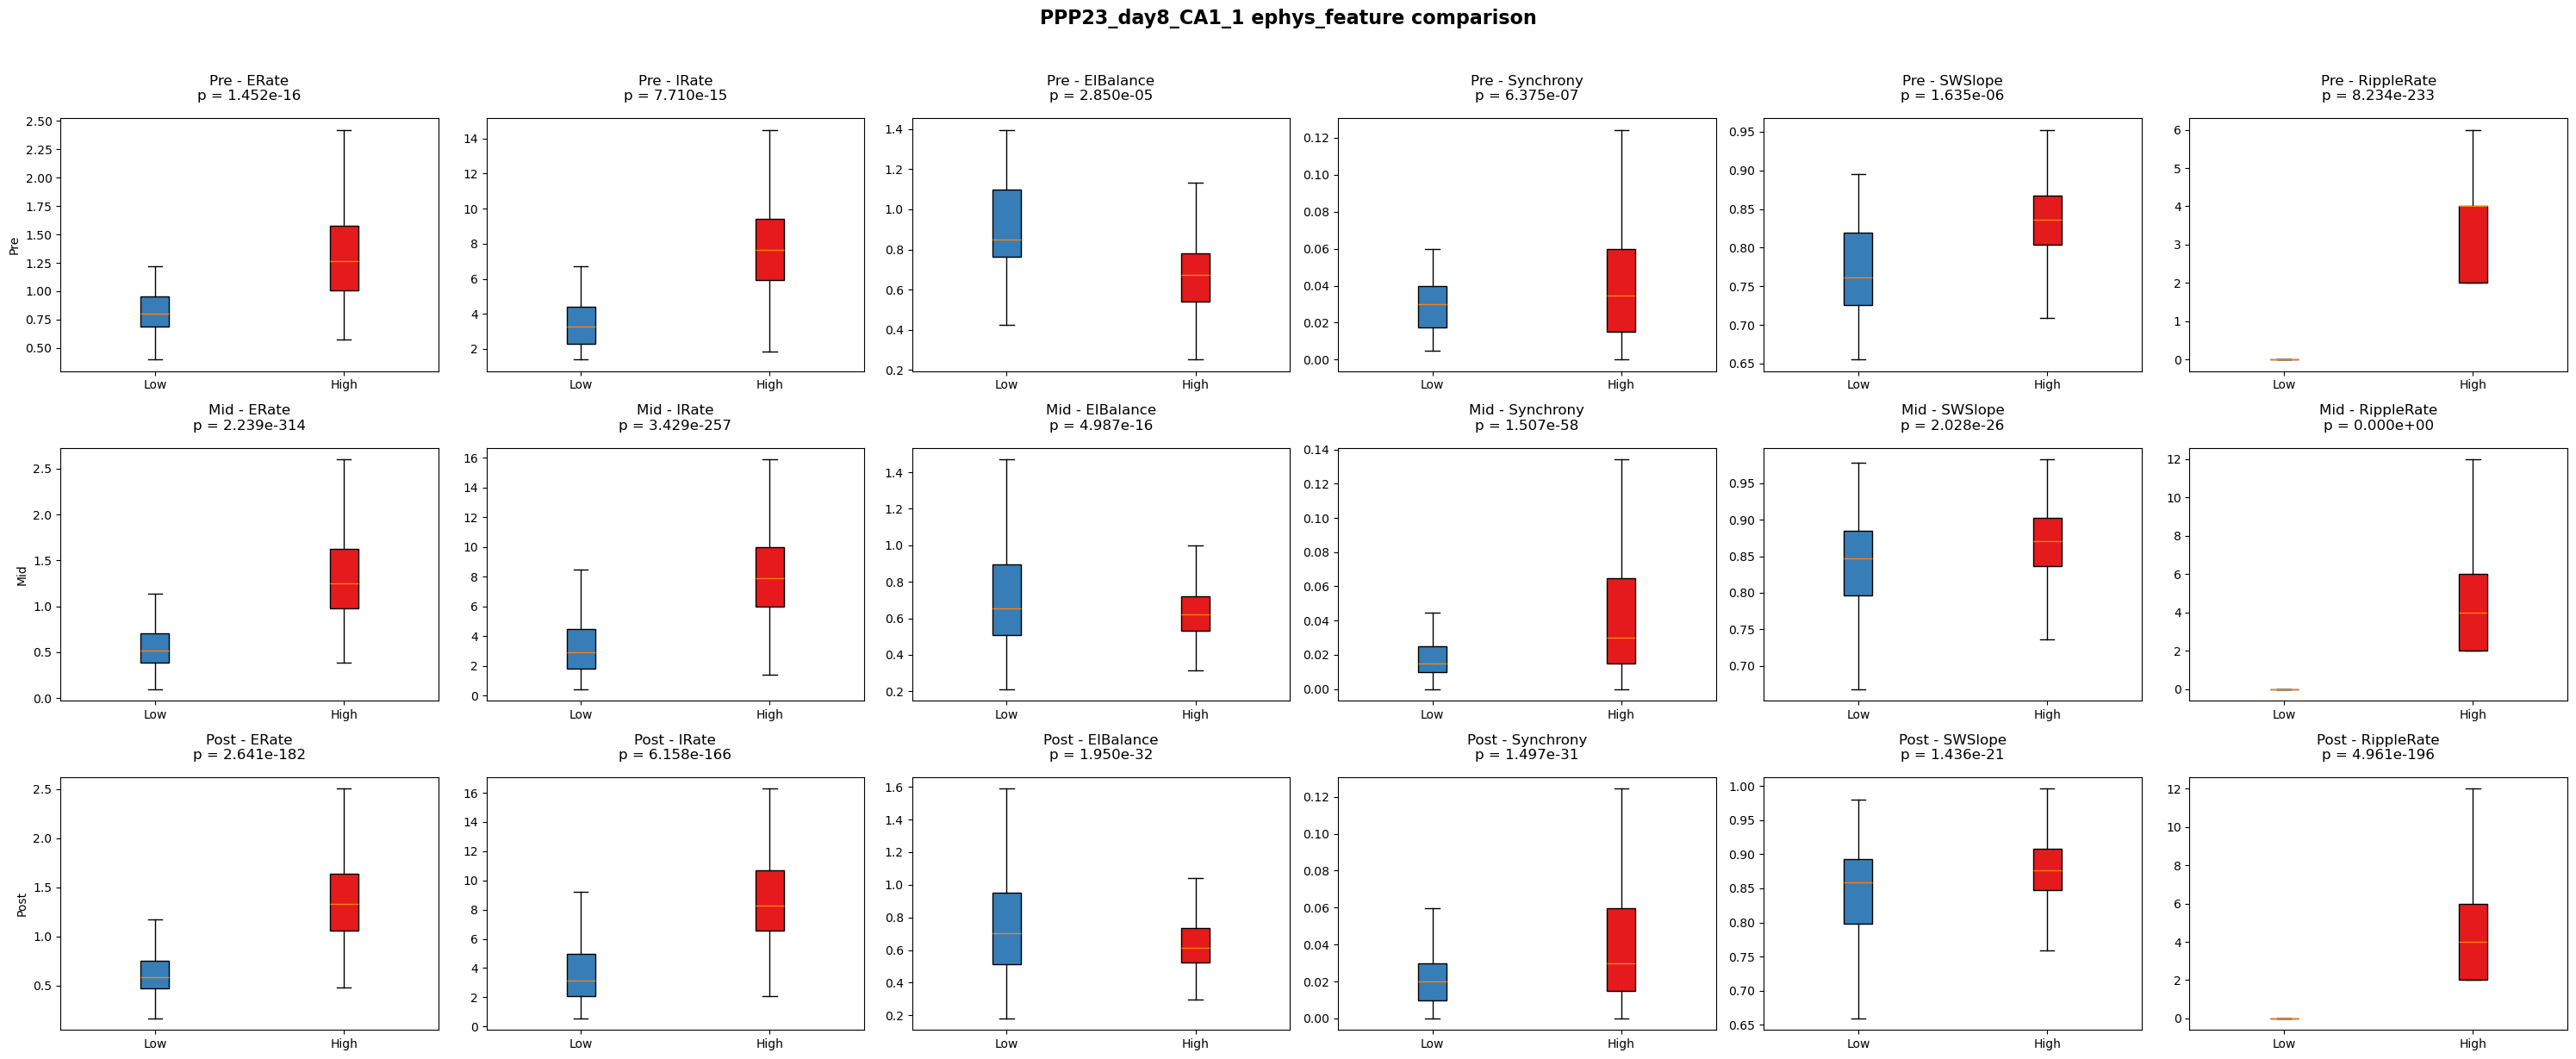

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
# --- df built as above ---
# For convenience, add a time column to df using the concatenated timestamps
df['Time'] = all_timestamps

# ---------------------------
# Helper function to filter a DataFrame by a list of intervals
# ---------------------------
def filter_df_by_intervals(df, intervals):
    """
    Given a DataFrame with a 'Time' column and a list of intervals (tuples of (start, end)),
    return a DataFrame with only the rows where the time is within any of the intervals.
    """
    mask = np.zeros(len(df), dtype=bool)
    for start, end in intervals:
        mask |= (df['Time'] >= start) & (df['Time'] <= end)
    return df[mask]

# ---------------------------
# Sleep periods and corresponding intervals.
# It is assumed that the variables pre_low_equal, pre_high_equal, mid_low_equal, mid_high_equal,
# post_low_equal, post_high_equal are already defined.
# ---------------------------
sleep_periods = {
    "Pre": {"low": pre_low_equal, "high": pre_high_equal},
    "Mid": {"low": mid_low_equal, "high": mid_high_equal},
    "Post": {"low": post_low_equal, "high": post_high_equal}
}

# ---------------------------
# Parameters to plot.
# These match the DataFrame's column names.
# ---------------------------
params = ["ERate", "IRate", "EIBalance", "Synchrony", "SWSlope", "RippleRate"]

# ---------------------------
# For each sleep period and condition, extract the data that falls within the given intervals.
# ---------------------------
filtered_data = {}
for period, conditions in sleep_periods.items():
    filtered_data[period] = {}
    for cond, intervals in conditions.items():
        filtered_data[period][cond] = filter_df_by_intervals(df, intervals)

# ---------------------------
# Create subplots: 3 rows (one per sleep period) and one column per parameter.
# In each subplot, we will draw a box plot comparing low vs. high conditions.
# ---------------------------
n_rows = len(sleep_periods)
n_cols = len(params)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
fig.suptitle(f"{animal_name}_{day}_{brain_region}_{current_bin_size} ephys_feature comparison", fontsize=16, fontweight='bold', y=1.02)

# Ensure axes is 2D (if only one row or one column, adjust accordingly)
if n_rows == 1:
    axes = axes[np.newaxis, :]
if n_cols == 1:
    axes = axes[:, np.newaxis]
palette = {"low_ripple": sns.color_palette("Set1")[1], "high_ripple": sns.color_palette("Set1")[0]}
# Loop over sleep periods and parameters, then plot the boxplots.

# Loop over sleep periods and parameters, then plot the boxplots.
for row, period in enumerate(["Pre", "Mid", "Post"]):
    for col, param in enumerate(params):
        ax = axes[row, col]

        # Extract the parameter values for both conditions (drop NaNs if any)
        low_values = filtered_data[period]["low"][param].dropna().values if param in filtered_data[period]["low"].columns else np.array([])
        high_values = filtered_data[period]["high"][param].dropna().values if param in filtered_data[period]["high"].columns else np.array([])

        # Perform t-test between low and high conditions
        if len(low_values) > 1 and len(high_values) > 1:
            t_stat, p_value = ttest_ind(low_values, high_values, equal_var=False, nan_policy='omit')
            p_text = f"p = {p_value:.3e}" if p_value < 0.001 else f"p = {p_value:.3f}"
        else:
            p_text = "p = NA"  # Not enough data for t-test

        # Create the boxplot
        bp = ax.boxplot([low_values, high_values], labels=["Low", "High"], showfliers=False, patch_artist=True)

        # Customize colors
        colors = [palette["low_ripple"], palette["high_ripple"]]
        for patch, color in zip(bp['boxes'], colors):
            patch.set_facecolor(color)

        # Set title and p-value annotation
        ax.set_title(f"{period} - {param}")
        ax.set_title(f"{period} - {param}\n{p_text}", fontsize=12, pad=15)
        # Optionally, label the y-axis only on the leftmost column.
        if col == 0:
            ax.set_ylabel(period)

file_path = r"D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples\control"
file_name = f"{animal_name}_{day}_{brain_region}_{current_bin_size}_ephys_control.png"
full_path = os.path.join(file_path, file_name)

# Adjust layout and save the plot
plt.tight_layout()
plt.savefig(full_path, dpi=300)  # Save with high resolution
plt.show()

In [10]:
filtered_data

{'Pre': {'low':         UMAP1     UMAP2 Condition  RippleRate     ERate     IRate  EIBalance  \
  10   7.793046  5.469520       Pre         0.0  0.641791  3.792453   0.641791   
  11   7.836389  5.397284       Pre         0.0  0.930348  4.377358   0.806034   
  12   7.889225  5.357272       Pre         0.0  0.656716  4.433962   0.561702   
  13   7.928403  5.356493       Pre         0.0  1.039801  5.075472   0.776952   
  14   7.913979  5.325169       Pre         0.0  0.701493  3.132075   0.849398   
  20   7.821155  5.422737       Pre         0.0  0.825871  3.150943   0.994012   
  21   7.847110  5.377511       Pre         0.0  0.800995  4.339623   0.700000   
  23   7.974380  5.360537       Pre         0.0  0.875622  3.018868   1.100000   
  24   7.962140  5.348225       Pre         0.0  1.069652  5.264151   0.770609   
  25   7.981996  5.327729       Pre         0.0  1.064677  6.735849   0.599440   
  26   7.949616  5.307700       Pre         0.0  0.990050  4.226415   0.888393   
  

In [9]:
import pandas as pd
import pickle
import os

# Define the base path
file_path = r"D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples\control"

# Construct unique file name based on condition
file_name = f"ephys_feature_lh_data_{animal_name}_{day}_{brain_region}_{current_bin_size}.pkl"
full_path = os.path.join(file_path, file_name)

# --- Save filtered_data directly ---
try:
    os.makedirs(file_path, exist_ok=True)
    with open(full_path, 'wb') as f:
        pickle.dump(filtered_data, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"✅ Saved: {file_name}")
except Exception as e:
    print(f"❌ Error saving data: {e}")


✅ Saved: ephys_feature_lh_data_PPP23_day8_CA1_1.pkl
